Média simulada: 10.51%
Mediana simulada: 8.26%
σ = 20%: 8.33%
σ = 40%: 2.02%


σ = 20%, 10 anos: 10.3%
σ = 60%, 30 anos: 76.7%


σ = 15%: f* = 3.11 | g* = 13.89%
σ = 20%: f* = 1.75 | g* = 9.12%
σ = 30%: f* = 0.78 | g* = 5.72%
σ = 40%: f* = 0.44 | g* = 4.53%
σ = 60%: f* = 0.19 | g* = 3.68%


Média do log-retorno em 1 ano: 0.011
Desvio do log-retorno em 1 ano: 0.208
Curtose em excesso: 3.11


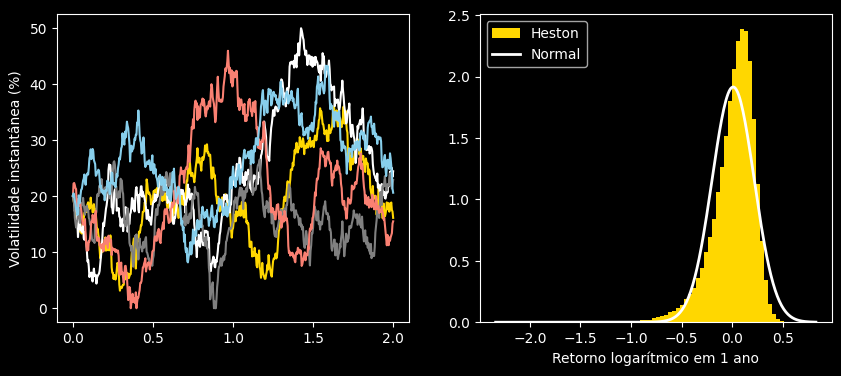

Vol. implícita, 1 ano: [23.2 22.1 21.1 20.1 19.1 18.2 17.4 16.6 15.9]


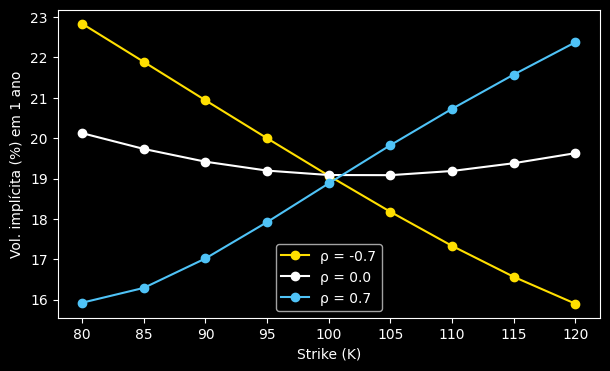

In [2]:
# Ativa o modo padrão para Matplotlib (sem necessidade de widgets problemáticos)
%matplotlib inline

# Passo 1: parâmetros e conferência
import numpy as np
from math import erf, sqrt
import matplotlib.pyplot as plt
import plotly.graph_objects as go

rng = np.random.default_rng(42)
mu = 0.10        # retorno esperado ao ano
sigma = 0.20     # volatilidade ao ano
T = 1.0          # horizonte em anos
Z = rng.standard_normal(200_000)
drift = (mu - sigma**2 / 2) * T
S = np.exp(drift + sigma * np.sqrt(T) * Z)
print(f"Média simulada: {S.mean() - 1:.2%}")
print(f"Mediana simulada: {np.median(S) - 1:.2%}")

# Passo 2: a fórmula e a grade
def crescimento(mu, sigma):
    return np.exp(mu - sigma**2 / 2) - 1

vols = np.linspace(0.05, 0.60, 56)
rets = np.linspace(0, 0.20, 41)
V, M = np.meshgrid(vols, rets)
G = crescimento(M, V) * 100
print(f"σ = 20%: {crescimento(0.10, 0.20):.2%}")
print(f"σ = 40%: {crescimento(0.10, 0.40):.2%}")

# Código do gráfico 1 (Interativo com Plotly)
fig1 = go.Figure(data=[go.Surface(x=V * 100, y=M * 100, z=G, colorscale='YlOrBr')])
fig1.update_layout(
    title='Crescimento Mediano (%)',
    scene=dict(
        xaxis_title='Volatilidade (%)',
        yaxis_title='Retorno esperado (%)',
        zaxis_title='Crescimento mediano (%)'
    ),
    width=700,
    height=500,
    template='plotly_dark'
)
fig1.show()

# Passo 3: a chance de perder
def cdf(x):
    return 0.5 * (1 + np.vectorize(erf)(x / sqrt(2)))

def prob_perda(sigma, T, mu=0.10):
    z = (mu - sigma**2 / 2) * np.sqrt(T) / sigma
    return cdf(-z)

anos = np.linspace(1, 30, 30)
H, VH = np.meshgrid(anos, vols)
P = prob_perda(VH, H) * 100
print(f"σ = 20%, 10 anos: {prob_perda(0.20, 10):.1%}")
print(f"σ = 60%, 30 anos: {prob_perda(0.60, 30):.1%}")

# Código do gráfico 2 (Interativo com Plotly)
fig2 = go.Figure(data=[go.Surface(x=VH * 100, y=H, z=P, colorscale='YlOrBr')])
fig2.update_layout(
    title='Chance de Perder (%)',
    scene=dict(
        xaxis_title='Volatilidade (%)',
        yaxis_title='Horizonte (anos)',
        zaxis_title='Chance de perder (%)'
    ),
    width=700,
    height=500,
    template='plotly_dark'
)
fig2.show()

# Passo 4: a fração de Kelly
rf = 0.03

def cresc_f(f, sigma, mu=0.10):
    return rf + f * (mu - rf) - 0.5 * (f * sigma) ** 2

def kelly(sigma, mu=0.10):
    return (mu - rf) / sigma**2

for s in (0.15, 0.20, 0.30, 0.40, 0.60):
    fs = kelly(s)
    g = cresc_f(fs, s)
    print(f"σ = {s:.0%}: f* = {fs:.2f} | g* = {g:.2%}")

# Código do gráfico 3 (Interativo com Plotly)
fs = np.linspace(0, 3, 61)
vs = np.linspace(0.15, 0.60, 46)
F, VF = np.meshgrid(fs, vs)
Gk = np.maximum(cresc_f(F, VF) * 100, -10)
fopt = np.minimum(kelly(vs), 3)
gopt = cresc_f(fopt, vs) * 100

fig3 = go.Figure(data=[
    go.Surface(x=F, y=VF * 100, z=Gk, colorscale='YlOrBr', name='Superfície'),
    go.Scatter3d(x=fopt, y=vs * 100, z=gopt, mode='lines', line=dict(color='white', width=5), name='Ótimo')
])
fig3.update_layout(
    title='Crescimento (%) vs Fração e Volatilidade',
    scene=dict(
        xaxis_title='Fração na ação (f)',
        yaxis_title='Volatilidade (%)',
        zaxis_title='Crescimento (%)'
    ),
    width=700,
    height=500,
    template='plotly_dark'
)
fig3.show()

# Passo 5: parâmetros de Heston
S0, r = 100.0, 0.03
v0, kappa, theta, xi = 0.04, 2.0, 0.04, 0.4
passos_ano = 252

# Passo 6: simulando Heston
def heston(n, T, rho, guardar=()):
    dt = 1 / passos_ano
    S = np.full(n, S0)
    v = np.full(n, v0)
    vols5, salvos = [v[:5].copy()], {}
    for t in range(1, int(T * passos_ano) + 1):
        z1 = rng.standard_normal(n)
        z3 = rng.standard_normal(n)
        z2 = rho * z1 + np.sqrt(1 - rho**2) * z3
        vp = np.maximum(v, 0)
        raiz = np.sqrt(vp * dt)
        S = S * np.exp((r - vp / 2) * dt + raiz * z1)
        mov_v = kappa * (theta - vp) * dt
        v = v + mov_v + xi * raiz * z2
        vols5.append(v[:5].copy())
        if t in guardar:
            salvos[t] = S.copy()
    return np.array(vols5), salvos

# Passo 7: rodando e medindo
vols5, salvos = heston(200_000, 2.0, -0.7, {252})
lr = np.log(salvos[252] / S0)
m, s = lr.mean(), lr.std()
curtose = ((lr - m) ** 4).mean() / s**4 - 3
print(f"Média do log-retorno em 1 ano: {m:.3f}")
print(f"Desvio do log-retorno em 1 ano: {s:.3f}")
print(f"Curtose em excesso: {curtose:.2f}")

# Código do gráfico 4
plt.style.use("dark_background")
plt.rcParams["grid.color"] = "#444444"

t = np.arange(len(vols5)) / passos_ano
sig_t = np.sqrt(np.maximum(vols5, 0)) * 100
x = np.linspace(lr.min(), lr.max(), 300)
z = (x - m) / s
pdf = np.exp(-z**2 / 2) / (s * np.sqrt(2 * np.pi))
cores5 = ["gold", "white", "gray", "salmon", "skyblue"]

fig, (a, b) = plt.subplots(1, 2, figsize=(10, 4))
a.set_prop_cycle(color=cores5)
a.plot(t, sig_t)
a.set_ylabel("Volatilidade instantânea (%)")
b.hist(lr, bins=80, density=True, color="gold", label="Heston")
b.plot(x, pdf, "w", lw=2, label="Normal")
b.set_xlabel("Retorno logarítmico em 1 ano")
b.legend()
plt.show()

# Passo 8: volatilidade implícita
def bs_call(K, T, vol):
    raiz = vol * np.sqrt(T)
    d1 = (np.log(S0 / K) + (r + vol**2 / 2) * T) / raiz
    d2 = d1 - raiz
    return S0 * cdf(d1) - K * np.exp(-r * T) * cdf(d2)

def vol_impl(preco, K, T):
    lo, hi = 0.01, 1.5
    for _ in range(50):
        meio = (lo + hi) / 2
        acima = bs_call(K, T, meio) > preco
        hi = np.where(acima, meio, hi)
        lo = np.where(acima, lo, meio)
    return (lo + hi) / 2

# Passo 9: a superfície K × T
Ks = np.arange(80, 121, 5)
Ts = np.array([0.25, 0.5, 0.75, 1.0, 1.25, 1.5, 1.75, 2.0])

def vol_surface(rho, Ts, n=200_000):
    passos = [int(t * passos_ano) for t in Ts]
    _, salvos = heston(n, max(Ts), rho, set(passos))
    iv = np.zeros((len(Ts), len(Ks)))
    for i, (t, p) in enumerate(zip(Ts, passos)):
        pay = np.maximum(salvos[p][:, None] - Ks, 0)
        preco = np.exp(-r * t) * pay.mean(axis=0)
        iv[i] = vol_impl(preco, Ks, t) * 100
    return iv

iv = vol_surface(-0.7, Ts)
print("Vol. implícita, 1 ano:", iv[3].round(1))

# Código do gráfico 5 (Interativo com Plotly)
KK, TT = np.meshgrid(Ks, Ts)

fig5 = go.Figure(data=[go.Surface(x=KK, y=TT, z=iv, colorscale='YlOrBr')])
fig5.update_layout(
    title='Superfície de Volatilidade Implícita',
    scene=dict(
        xaxis_title='Strike (K)',
        yaxis_title='Vencimento (anos)',
        zaxis_title='Vol. implícita (%)'
    ),
    width=700,
    height=500,
    template='plotly_dark'
)
fig5.show()

# Código do gráfico 6
cores = {-0.7: "#FFDF00", 0.0: "white", 0.7: "#4FC3F7"}

dados = {}
plt.figure(figsize=(7, 4))
for rho_i, cor in cores.items():
    smile = vol_surface(rho_i, [1.0])[0]
    dados[rho_i] = smile
    plt.plot(Ks, smile, "o-", color=cor, label=f"ρ = {rho_i}")
plt.xlabel("Strike (K)")
plt.ylabel("Vol. implícita (%) em 1 ano")
plt.legend()
plt.show()